# 04 - The supervised extractor

Why v3 loses on its 3 worst datasets, what each part of v4's extractor adds and which features it keeps.

## 1. Data

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import (BETTER, COLORS, EQUAL, MUTED, OTHERS, OUTCOME_COLORS, DATA_TS, REPO, RESULTS_DIR, TEXT, VERSION_COLORS, WORSE,
                    change_color, dataset_list, holm, load_runs, read_split, signed, style, wdl_counts)

style()
key = ["dataset", "resample"]
WORST3 = dataset_list("worst3")
DEV = dataset_list("dev34")
DATASETS = (REPO / "original" / "code" / "ucr142.txt").read_text().split()

def load(name):
    d = load_runs(RESULTS_DIR / name)
    return d[d["status"] == "ok"]

full_runs = {"QUANT + ExtraTrees": load("v1_ucr142_allcores-cpu.csv"),                 # the full runs of notebook 05
             "v3 (cheap TabPFN)": load("v3_tabpfn-e2f200-both_ucr142_allcores-gpu.csv"),
             "v4": load("v4_tabpfn-e2f200_ucr142_allcores-gpu.csv")}

# the ablation: v4 with one part switched off (file name -> what is switched off)
ABLATION = {"catch22": "without catch22", "templates": "without the pattern templates",
            "lags": "without the lag-d views", "fill": "without filling the budget",
            "rank": "ANOVA order only (no ExtraTrees importance)", "quantiles": "min and max only (no fifth of QUANT's quantiles)"}
ABLATION_RUNS = {part: load(f"v4-abl-{part}_tabpfn-e2f200_dev34_allcores-gpu.csv") for part in ABLATION}

# what happened to the candidates of v4 (per dataset, source and outcome, the mean per run), from its selection log;
# the log of the full run (about 200 MB) is not in the repository, the summary made from it is
SUMMARY = RESULTS_DIR / "v4_tabpfn-e2f200_ucr142_allcores-gpu_selection-summary.csv"
LOG = RESULTS_DIR / "v4_tabpfn-e2f200_ucr142_allcores-gpu_selection.csv"
if LOG.exists():
    s = pd.read_csv(LOG, usecols=["dataset", "resample", "source", "outcome", "count"])
    runs = s.groupby("dataset")["resample"].nunique()                       # number of runs of each dataset
    summary = s.groupby(["dataset", "source", "outcome"])["count"].sum().reset_index()
    summary["per_run"] = summary["count"] / summary["dataset"].map(runs)    # map: look up each row's dataset
    summary.drop(columns="count").to_csv(SUMMARY, index=False, float_format="%.4g")
SELECTION = pd.read_csv(SUMMARY)

## 2. Why v3 loses on its 3 worst datasets

ShapeletSim, ToeSegmentation1, and ToeSegmentation2 have two classes, 20 to 40 training cases, and a short pattern at a varying position. Two
diagnostic runs that separate the classifier from the features are shown below, ExtraTrees on v3's features, and TabPFN on QUANT's own features.

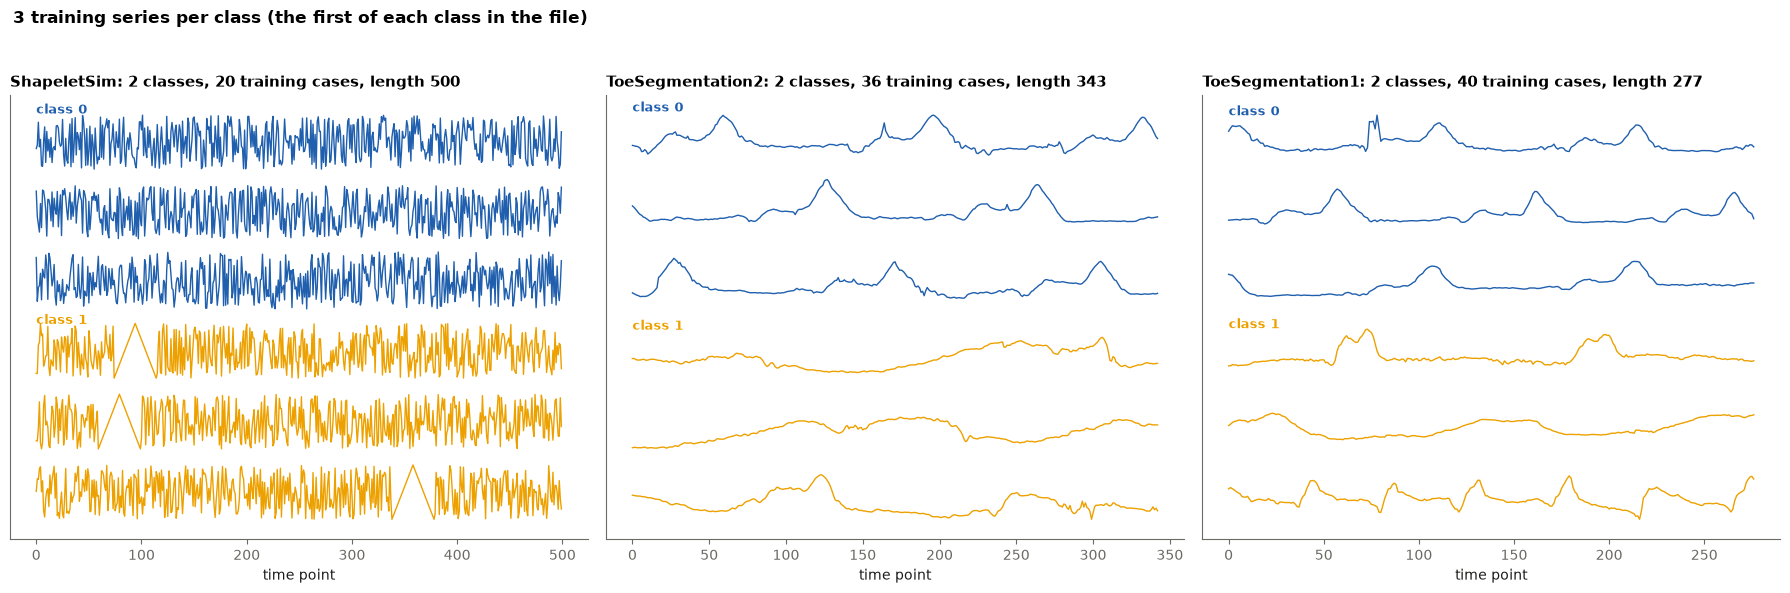

In [3]:
def read_series(name, split):
    """The series (one row each) and the class labels of <name>_<split>.ts."""
    lines = (DATA_TS / name / f"{name}_{split}.ts").read_text(encoding="utf-8").splitlines()
    start = 0
    while lines[start].strip().lower() != "@data":       # skip the header
        start += 1
    X, y = [], []
    for line in lines[start + 1:]:
        if line.strip():
            values, label = line.rsplit(":", 1)          # "v1,v2,...:label"
            X.append([float(v) for v in values.split(",")])
            y.append(label.strip())
    return np.array(X), np.array(y)


PER_CLASS = 3                                            # training series drawn per class
CLASS_COLORS = [VERSION_COLORS["v1"], COLORS["tabpfn"]]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, name in zip(axes, WORST3):
    X, y = read_series(name, "TRAIN")
    classes = sorted(set(y))
    spacing = 1.2 * (X.max() - X.min())                  # vertical gap between the series
    row = 0
    for k, label in enumerate(classes):
        series = X[y == label][:PER_CLASS]
        for s in series:
            ax.plot(s - row * spacing, color=CLASS_COLORS[k], linewidth=1)
            row += 1
        # the class name next to its first series
        ax.annotate(f"class {label}", (0, -(row - PER_CLASS) * spacing + 0.4 * spacing), fontsize=9,
                    color=CLASS_COLORS[k], fontweight="bold")
    ax.set_yticks([])
    ax.set_xlabel("time point")
    ax.set_title(f"{name}: {len(classes)} classes, {len(y)} training cases, length {X.shape[1]}", loc="left")
    ax.grid(False)
fig.suptitle(f"{PER_CLASS} training series per class (the first of each class in the file)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


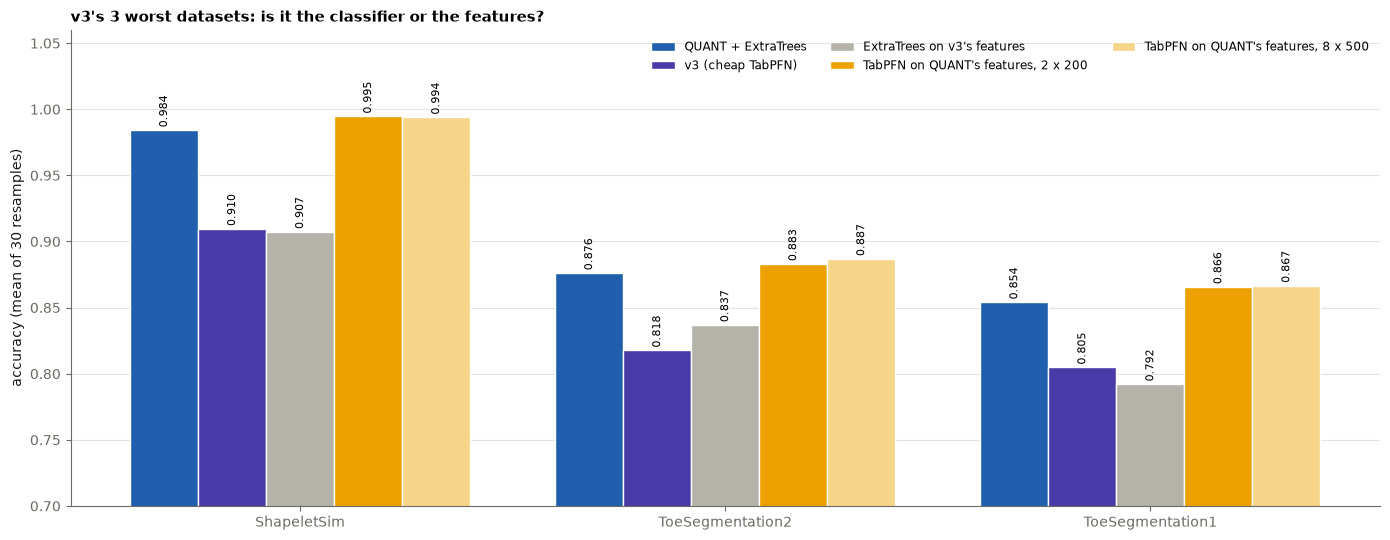

In [4]:
DIAGNOSIS = {"QUANT + ExtraTrees": full_runs["QUANT + ExtraTrees"],
             "v3 (cheap TabPFN)": full_runs["v3 (cheap TabPFN)"],
             "ExtraTrees on v3's features": load("v3_extratrees_worst3_allcores-cpu.csv"),
             "TabPFN on QUANT's features, 2 x 200": load("v2_tabpfn-e2f200-cache_worst3_allcores-gpu.csv"),
             "TabPFN on QUANT's features, 8 x 500": load("v2_tabpfn-e8f500-cache_worst3_allcores-gpu.csv")}
DIAGNOSIS_COLORS = [VERSION_COLORS["v1"], VERSION_COLORS["v3"], OTHERS, COLORS["tabpfn"], COLORS["tabpfn default"]]
fig, ax = plt.subplots(figsize=(14, 5.5))
width = 0.16
for k, (label, runs) in enumerate(DIAGNOSIS.items()):
    color = DIAGNOSIS_COLORS[k]
    values = runs[runs["dataset"].isin(WORST3)].groupby("dataset")["accuracy"].mean().reindex(WORST3)
    bars = ax.bar(np.arange(3) + (k - 2) * width, values, width, color=color, edgecolor="white", label=label)
    ax.bar_label(bars, fmt="{:.3f}", padding=2, fontsize=8, rotation=90)
ax.set_xticks(range(3), WORST3)
ax.set_ylim(0.7, 1.06)
ax.set_ylabel("accuracy (mean of 30 resamples)")
ax.set_title("v3's 3 worst datasets: is it the classifier or the features?", loc="left")
ax.legend(loc="upper right", ncol=3, frameon=False, fontsize=8.5)
ax.grid(True, axis="y")
ax.grid(False, axis="x")
fig.tight_layout()
plt.show()

The cause is v3's feature extractor, not TabPFN. ExtraTrees loses on them too when given v3 features, while TabPFN on QUANT's original features beats QUANT + ExtraTrees. v3's coarse pieces average the short pattern away so catch22 and the pattern templates were added to counter this issue in later versions.

## 3. The ablation: what each part of v4 adds

Most of the diagnostic runs needed to develop v4 were compacted in this ablation to demonstrate what each part of v4 brings in. So we run v4 with one part switched off, on the 34 development datasets, resamples 0 to 9, against v4 on the same runs. 

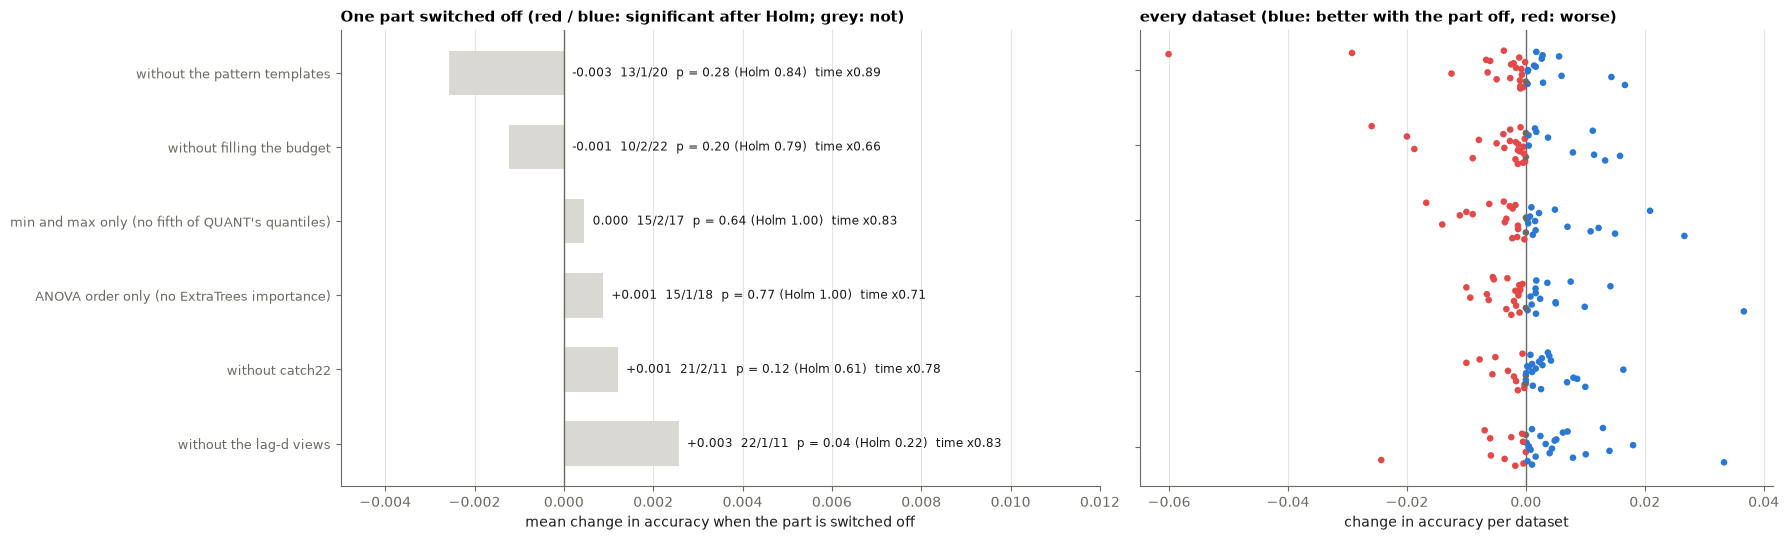

In [5]:
v4_dev = full_runs["v4"][full_runs["v4"]["dataset"].isin(DEV) & (full_runs["v4"]["resample"] < 10)]
rows = []
for part, label in ABLATION.items():
    both = ABLATION_RUNS[part].merge(v4_dev, on=key, suffixes=("", "_v4"))
    per_dataset = both.groupby("dataset")[["accuracy", "accuracy_v4", "total_time", "total_time_v4"]].mean()
    change = per_dataset["accuracy"] - per_dataset["accuracy_v4"]
    better, equal, worse = wdl_counts(change)
    rows.append({"part": label, "change": change, "mean": change.mean(), "wdl": (better, equal, worse),
                 "p": stats.wilcoxon(per_dataset["accuracy"], per_dataset["accuracy_v4"]).pvalue,
                 "time": per_dataset["total_time"].sum() / per_dataset["total_time_v4"].sum(), "runs": len(both)})
rows.sort(key=lambda r: r["mean"])                       # sort by the mean change: the most harmful loss first
adjusted = holm(pd.Series([r["p"] for r in rows]))      # Holm's correction for the six tests
for k, r in enumerate(rows):
    r["holm"] = adjusted[k]


def ablation_color(r):
    """Red / blue: worse / better without the part, significant after Holm; grey: not significant."""
    if r["holm"] >= 0.05:
        return EQUAL
    return change_color(r["mean"])



fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
y = np.arange(len(rows))[::-1]
ax = axes[0]
ax.barh(y, [r["mean"] for r in rows], 0.6, color=[ablation_color(r) for r in rows])
for yy, r in zip(y, rows):
    ax.annotate(f"{signed(r['mean'])}  {r['wdl'][0]}/{r['wdl'][1]}/{r['wdl'][2]}  p = {r['p']:.2f} (Holm {r['holm']:.2f})  "
                f"time x{r['time']:.2f}",
                (max(r["mean"], 0), yy), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=TEXT)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [r["part"] for r in rows], fontsize=9)
ax.set_xlim(min(-0.005, min(r["mean"] for r in rows) * 1.4), 0.012)
ax.set_xlabel("mean change in accuracy when the part is switched off")
ax.set_title("One part switched off (red / blue: significant after Holm; grey: not)", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax = axes[1]
for yy, r in zip(y, rows):
    n = len(r["change"])
    heights = yy + np.linspace(-0.25, 0.25, n)                # spread the points a little around the row
    colors = [MUTED if abs(c) <= 1e-12 else change_color(c) for c in r["change"]]
    ax.scatter(r["change"], heights, s=14, color=colors, zorder=3)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [])
ax.set_xlabel("change in accuracy per dataset")
ax.set_title("every dataset (blue: better with the part off, red: worse)", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

## 4. What v4 keeps, and why the other candidates are dropped

All 142 datasets of v4's full run, the mean per run. Left: what happens to the candidates of every source; right:
where the kept features come from.

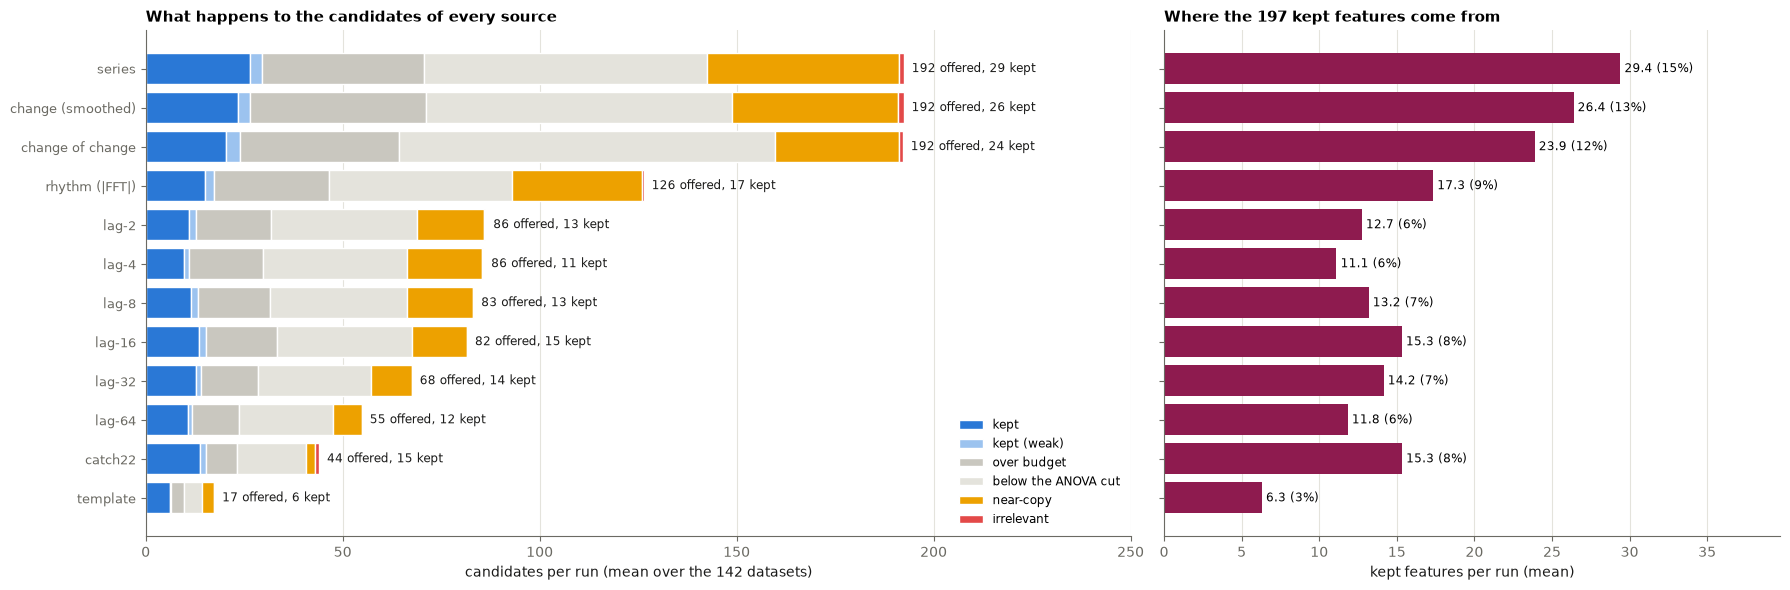

In [6]:
LAG_VIEWS = ["lag-2", "lag-4", "lag-8", "lag-16", "lag-32", "lag-64"]
SOURCES = ["series", "change (smoothed)", "change of change", "rhythm (|FFT|)"] + LAG_VIEWS + ["catch22", "template"]
OUTCOMES = OUTCOME_COLORS
per_source = SELECTION.groupby(["source", "outcome"])["per_run"].sum()
per_source = per_source.unstack(fill_value=0) / len(DATASETS)          # unstack: one row per source, one column per outcome
per_source = per_source.reindex(index=SOURCES, columns=list(OUTCOMES)).fillna(0)   # in our order, 0 where missing

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
y = np.arange(len(SOURCES))[::-1]
left = np.zeros(len(SOURCES))
for outcome, color in OUTCOMES.items():
    ax.barh(y, per_source[outcome], left=left, color=color, edgecolor="white", label=outcome)
    left += per_source[outcome].values
for yy, total, kept in zip(y, left, per_source["kept"] + per_source["kept (weak)"]):
    ax.text(total, yy, f"  {total:,.0f} offered, {kept:.0f} kept", va="center", fontsize=8.5, color=TEXT)
ax.set_yticks(y, SOURCES, fontsize=9)
ax.set_xlim(0, left.max() * 1.3)
ax.set_xlabel("candidates per run (mean over the 142 datasets)")
ax.set_title("What happens to the candidates of every source", loc="left")
ax.legend(loc="lower right", frameon=False, fontsize=8.5)
ax.grid(True, axis="x")
ax.grid(False, axis="y")
ax = axes[1]
kept = per_source["kept"] + per_source["kept (weak)"]
bars = ax.barh(y, kept, color=VERSION_COLORS["v4"])
ax.bar_label(bars, labels=[f"{v:.1f} ({100 * v / kept.sum():.0f}%)" for v in kept], padding=3, fontsize=8.5)
ax.set_yticks(y, [])
ax.set_xlim(0, kept.max() * 1.35)
ax.set_xlabel("kept features per run (mean)")
ax.set_title(f"Where the {kept.sum():.0f} kept features come from", loc="left")
ax.grid(True, axis="x")
ax.grid(False, axis="y")
fig.tight_layout()
plt.show()

## 5. Which lag-d views v4 uses, by series length

The mean number of kept features per run from each lag view, the datasets grouped by series length; empty: the lag
is too long for those series.

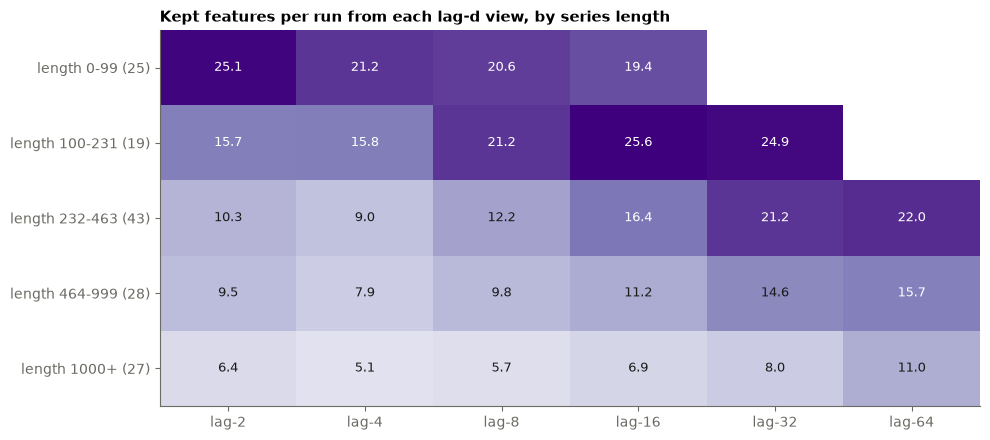

In [7]:
BINS = [(0, 100), (100, 232), (232, 464), (464, 1000), (1000, 100_000)]     # series lengths, [low, high)


def bin_name(lo, hi):
    return f"{lo}+" if hi == 100_000 else f"{lo}-{hi - 1}"


rows = [bin_name(lo, hi) for lo, hi in BINS]
bin_of = {}                                                    # dataset -> its length group
for d in DATASETS:
    length = read_split(d, "TRAIN")[1]
    for lo, hi in BINS:
        if lo <= length < hi:
            bin_of[d] = bin_name(lo, hi)
lags = SELECTION[SELECTION["source"].isin(LAG_VIEWS)].copy()
lags["length"] = lags["dataset"].map(bin_of)
offered = lags.groupby(["length", "source"])["dataset"].nunique().unstack()          # NaN: never offered
kept_rows = lags[lags["outcome"].str.startswith("kept")]
kept = kept_rows.groupby(["dataset", "source"])["per_run"].sum().unstack(fill_value=0)   # one row per dataset
kept = kept.reindex(index=DATASETS, columns=LAG_VIEWS, fill_value=0)
counts = pd.Series(bin_of).value_counts()                      # datasets per length group
table = kept.groupby(pd.Series(bin_of)).mean().reindex(index=rows, columns=LAG_VIEWS)
table = table.where(offered.reindex(index=rows, columns=LAG_VIEWS).notna())     # empty where never offered
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.imshow(table.values, cmap="Purples", vmin=0, vmax=np.nanmax(table.values), aspect="auto")
for r in range(len(rows)):
    for c in range(len(LAG_VIEWS)):
        v = table.values[r, c]
        if not np.isnan(v):
            ax.text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.6 * np.nanmax(table.values) else TEXT)
ax.set_xticks(range(len(LAG_VIEWS)), LAG_VIEWS)
ax.set_yticks(range(len(rows)), [f"length {r} ({counts.get(r, 0)})" for r in rows])
ax.set_title("Kept features per run from each lag-d view, by series length", loc="left")
ax.grid(False)
fig.tight_layout()
plt.show()